# EM27/SUN reference-data audit and quality control

Audit actual reference gas columns, reproduce dry-air mole fractions from gas/O2 column ratios and demonstrate sequential XAIR screening.

**Data provenance and limitations:** Only 26 reference rows across two days. These are precomputed retrievals, not measurements collected here. Synthetic anomalies are identified separately. The Jinja thresholds are a methodological demonstration and require site-specific validation.

This notebook runs the repository analysis and displays its saved results.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from analysis import run
metrics = run()
print(json.dumps(metrics, indent=2))

{
  "input_rows": 26,
  "utc_days": 2,
  "daily_stage_removed": 0,
  "hourly_stage_removed": 0,
  "accepted_rows": 26,
  "max_column_reconstruction_difference_ppm": {
    "XCO2": 0.001296936990456743,
    "XCH4": 6.830233392429719e-06,
    "XCO": 7.822874296126159e-07
  },
  "max_simple_ratio_difference_ppm": {
    "XCO2": 3.8772023615580338,
    "XCH4": 0.008511582694574749,
    "XCO": 0.002781046603745632
  },
  "reconstruction_note": "Uses documented AICF/angular/time-dependent oxygen corrections and the supplied XH2O. Remaining differences reflect rounded input/output fields; not an independent spectral retrieval.",
  "scope": "Real small reference dataset. Post-retrieval audit; not raw-to-column reprocessing.",
  "synthetic_anomaly_experiment_removed_rows": 1
}


reference_quality.png


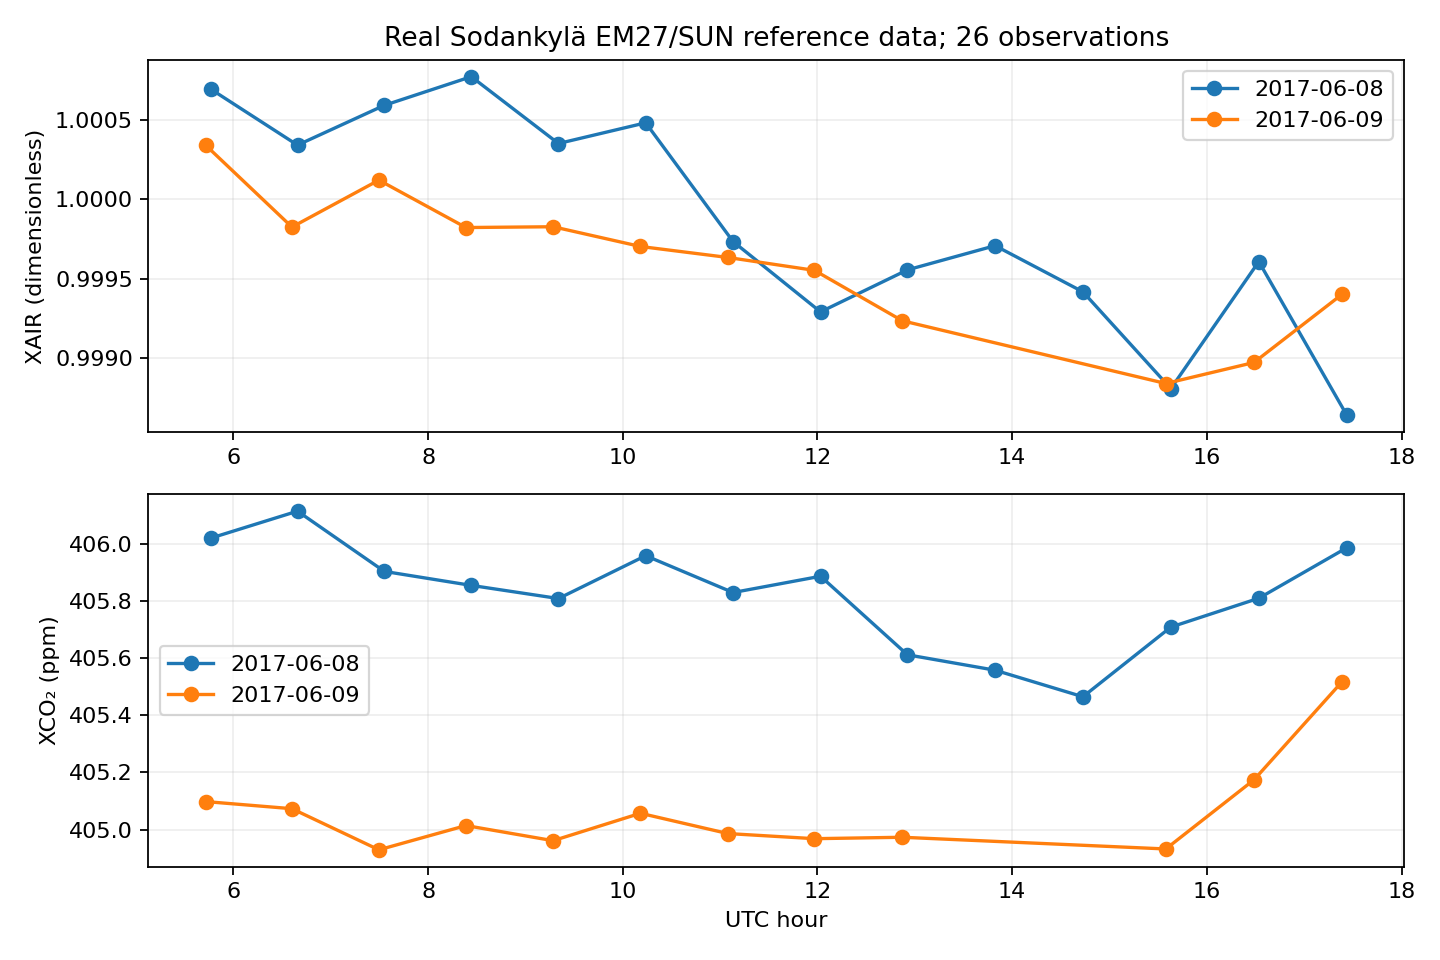

In [2]:
for path in sorted(Path('results').glob('*.png')):
    print(path.name)
    display(Image(filename=str(path)))

In [3]:
for path in sorted(Path('results').glob('*.csv')):
    print(path.name)
    display(pd.read_csv(path).head(10))

screened_observations.csv
synthetic_anomaly_experiment.csv


,UTC,LocalTime,spectrum,JulianDate,UTtimeh,gndP,gndT,latdeg,londeg,altim,appSZA,azimuth,XH2O,XAIR,XCO2,XCH4,XCO2_STR,XCO,XCH4_S5P,H2O,O2,CO2,CH4,CO,CH4_S5P,daily_reference,daily_pass,hourly_reference,hourly_pass,accepted,XCO2_simple_ratio,XCO2_reconstructed,XCH4_simple_ratio,XCH4_reconstructed,XCO_simple_ratio,XCO_reconstructed,XCH4_ppb,XCO_ppb
0,2017-06-08 05:46:19,2017-06-08 08:46:19,170608_054549SN.BIN,2.457913e+06,5.8,998.86,292.02,67.366,26.63,181.0,59.99,-77.41,1904.98,1.000690,406.021,1.80941,405.778,0.084571,1.81038,4.025020e+26,4.465610e+28,8.598710e+25,3.866300e+23,1.787110e+22,3.843490e+23,0.999721,True,1.000690,True,True,403.400598,406.020445,1.813839,1.809408,0.083841,0.084570,1809.41,84.5705
1,2017-06-08 06:39:31,2017-06-08 09:39:31,170608_063902SN.BIN,2.457913e+06,6.7,998.72,292.02,67.366,26.63,181.0,55.17,-64.06,1931.77,1.000340,406.115,1.81037,405.879,0.084038,1.81188,4.079580e+26,4.461340e+28,8.596950e+25,3.867310e+23,1.782100e+22,3.844700e+23,0.999721,True,1.000340,True,True,403.704050,406.114550,1.816050,1.810373,0.083686,0.084037,1810.37,84.0377
2,2017-06-08 07:33:02,2017-06-08 10:33:02,170608_073232SN.BIN,2.457913e+06,7.6,998.72,292.02,67.366,26.63,181.0,50.87,-49.59,1882.24,1.000590,405.904,1.80827,405.865,0.083617,1.80934,3.976090e+26,4.461220e+28,8.594570e+25,3.864260e+23,1.778600e+22,3.840120e+23,0.999721,True,1.000590,True,True,403.603143,405.903973,1.814666,1.808275,0.083523,0.083617,1808.27,83.6168
3,2017-06-08 08:26:38,2017-06-08 11:26:38,170608_082609SN.BIN,2.457913e+06,8.4,998.62,292.02,67.366,26.63,181.0,47.44,-33.89,1870.57,1.000770,405.855,1.80875,405.908,0.083703,1.80986,3.951750e+26,4.460720e+28,8.594200e+25,3.865830e+23,1.783720e+22,3.841450e+23,0.999721,True,1.000770,True,True,403.631006,405.855397,1.815607,1.808746,0.083773,0.083703,1808.75,83.7031
4,2017-06-08 09:20:22,2017-06-08 12:20:22,170608_091953SN.BIN,2.457913e+06,9.3,998.42,292.02,67.366,26.63,181.0,45.22,-17.04,1912.36,1.000350,405.809,1.80929,405.905,0.084469,1.81166,4.037470e+26,4.457410e+28,8.588190e+25,3.864790e+23,1.800650e+22,3.842870e+23,0.999721,True,1.000350,True,True,403.648263,405.809307,1.816466,1.809292,0.084631,0.084469,1809.29,84.4691
5,2017-06-08 10:14:07,2017-06-08 13:14:07,170608_101338SN.BIN,2.457913e+06,10.2,997.88,292.02,67.366,26.63,181.0,44.47,0.50,1874.49,1.000480,405.959,1.81478,406.353,0.086088,1.81725,3.955940e+26,4.455520e+28,8.587620e+25,3.874920e+23,1.834950e+22,3.853100e+23,0.999721,True,1.000480,True,True,403.792686,405.958762,1.822000,1.814775,0.086280,0.086088,1814.78,86.0881
6,2017-06-08 11:07:59,2017-06-08 14:07:59,170608_110729SN.BIN,2.457913e+06,11.1,997.52,292.02,67.366,26.63,181.0,45.30,18.06,1943.87,0.999734,405.830,1.81843,406.439,0.086417,1.82196,4.097670e+26,4.450570e+28,8.575740e+25,3.878430e+23,1.839290e+22,3.858860e+23,0.999721,True,0.999734,True,True,403.682569,405.830570,1.825679,1.818435,0.086580,0.086417,1818.43,86.4168
7,2017-06-08 12:01:54,2017-06-08 15:01:54,170608_120126SN.BIN,2.457913e+06,12.0,997.22,292.02,67.366,26.63,181.0,47.61,34.92,2125.66,0.999292,405.887,1.81707,406.709,0.087009,1.82190,4.477070e+26,4.447250e+28,8.571340e+25,3.872560e+23,1.848550e+22,3.855990e+23,0.999721,True,0.999292,True,True,403.776655,405.886476,1.824276,1.817071,0.087081,0.087009,1817.07,87.0089
8,2017-06-08 12:55:28,2017-06-08 15:55:28,170608_125459SN.BIN,2.457913e+06,12.9,997.02,292.02,67.366,26.63,181.0,51.10,50.53,2334.28,0.999556,405.612,1.81710,406.460,0.089086,1.82327,4.916120e+26,4.447830e+28,8.566910e+25,3.872650e+23,1.889230e+22,3.859290e+23,0.999721,True,0.999556,True,True,403.515342,405.611037,1.824081,1.817102,0.088986,0.089086,1817.10,89.0864
9,2017-06-08 13:49:29,2017-06-08 16:49:29,170608_134900SN.BIN,2.457913e+06,13.8,996.83,292.02,67.366,26.63,181.0,55.48,65.07,2280.73,0.999708,405.558,1.81455,406.599,0.088318,1.82174,4.803300e+26,4.449190e+28,8.564990e+25,3.866520e+23,1.867490e+22,3.855980e+23,0.999721,True,0.999708,True,True,403.301591,405.557974,1.820637,1.814556,0.087935

,UTC,XAIR,accepted
0,2017-06-08 05:46:19,1.000690,True
1,2017-06-08 06:39:31,1.000340,True
2,2017-06-08 07:33:02,1.000590,True
3,2017-06-08 08:26:38,1.005770,False
4,2017-06-08 09:20:22,1.000350,True
5,2017-06-08 10:14:07,1.000480,True
6,2017-06-08 11:07:59,0.999734,True
7,2017-06-08 12:01:54,0.999292,True
8,2017-06-08 12:55:28,0.999556,True
9,2017-06-08 13:49:29,0.999708,True


## Interpretation and next steps

Only 26 reference rows across two days. These are precomputed retrievals, not measurements collected here. Synthetic anomalies are identified separately. The Jinja thresholds are a methodological demonstration and require site-specific validation.

Use `results/metrics.json` and the displayed tables to report actual findings. Consult `REVIEW_GUIDE.md` before using the CV wording: **Audited real EM27/SUN reference retrievals, reconstructed dry-air gas fractions and implemented sequential XAIR quality screening with controlled anomaly tests.**

### Observed result

All 26 real reference records pass the demonstrated XAIR screening. One deliberately injected 0.005 XAIR anomaly is rejected in a separate synthetic experiment. The simple CO2/O2 ratio differs from reported XCO2 by up to **3.877 ppm**; including the documented postprocessing corrections reduces the maximum discrepancy to **0.00130 ppm**. This is a consistency audit using rounded reference fields and supplied XH2O, not an independent spectral retrieval.